# Project Sentinel — Canonical Three-Feature Reproducibility Benchmark

This is the official capstone notebook. It creates a separate staged candidate and **does not** replace the active legacy deployment artifact (`v1.0.0`). The task is historical hazardous-label classification, not collision or impact prediction.


## Reproducibility contract

Run from the repository root after installing `sentinel_training/requirements-canonical.txt`. The dataset path is portable: it first resolves the provided Downloads CSV relative to this project. All generated files are deterministic and are written only beneath `sentinel_training/`.


In [3]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

from sentinel_training.canonical_pipeline import (
    DEFAULT_DATASET_PATH, DEFAULT_LEGACY_METADATA_PATH, DEFAULT_LEGACY_MODEL_PATH,
    FEATURES, MODEL_PARAMETERS, SEEDS, STAGING_DIR, dataset_provenance, feature_schema, sha256_file,
    legacy_preservation_manifest, load_config, load_dataset, create_group_splits,
    evaluate,
)

config = load_config()
DATASET_PATH = DEFAULT_DATASET_PATH
print(f'Dataset: {DATASET_PATH}')
print('Canonical model inputs:', FEATURES)
print('Pinned model parameters:', MODEL_PARAMETERS)


Dataset: /Users/baburreyan/Downloads/neo (3).csv
Canonical model inputs: ('absolute_magnitude', 'relative_velocity', 'miss_distance')
Pinned model parameters: {'learning_rate': 0.03, 'max_iter': 150, 'max_leaf_nodes': 31, 'l2_regularization': 5, 'random_state': 42}


# Phase 1 — Data preprocessing, validation, and provenance

The supplied CSV is treated as the canonical project copy, but its source URL/release, field dictionary, and hazardous-label definition were not supplied. Units are therefore deployment-declared rather than source-verified. Names and identifiers are excluded from predictors.


In [5]:
frame = load_dataset(DATASET_PATH)
dataset_info = dataset_provenance(frame, DATASET_PATH)
legacy_info = legacy_preservation_manifest(DEFAULT_LEGACY_MODEL_PATH, DEFAULT_LEGACY_METADATA_PATH)
print(json.dumps({
    'shape': [dataset_info['rows'], len(dataset_info['columns'])],
    'columns': dataset_info['columns'],
    'dtypes': dataset_info['dtypes'],
    'missing_values': dataset_info['missing_values'],
    'duplicate_rows': dataset_info['exact_duplicate_rows'],
    'constant_columns': dataset_info['constant_columns'],
    'nonfinite_numeric_values': dataset_info['nonfinite_numeric_values'],
    'unique_asteroid_ids': dataset_info['unique_asteroid_ids'],
    'target_distribution': dataset_info['target_distribution'],
    'csv_sha256': dataset_info['sha256'],
    'legacy_v1_0_0_model_sha256': legacy_info['model_sha256'],
}, indent=2))


{
  "shape": [
    90836,
    10
  ],
  "columns": [
    "id",
    "name",
    "est_diameter_min",
    "est_diameter_max",
    "relative_velocity",
    "miss_distance",
    "orbiting_body",
    "sentry_object",
    "absolute_magnitude",
    "hazardous"
  ],
  "dtypes": {
    "id": "int64",
    "name": "object",
    "est_diameter_min": "float64",
    "est_diameter_max": "float64",
    "relative_velocity": "float64",
    "miss_distance": "float64",
    "orbiting_body": "object",
    "sentry_object": "bool",
    "absolute_magnitude": "float64",
    "hazardous": "bool"
  },
  "missing_values": {
    "id": 0,
    "name": 0,
    "est_diameter_min": 0,
    "est_diameter_max": 0,
    "relative_velocity": 0,
    "miss_distance": 0,
    "orbiting_body": 0,
    "sentry_object": 0,
    "absolute_magnitude": 0,
    "hazardous": 0
  },
  "duplicate_rows": 0,
  "constant_columns": [
    "orbiting_body",
    "sentry_object"
  ],
  "nonfinite_numeric_values": 0,
  "unique_asteroid_ids": 27423,
  "targe

# Phase 2 — Exploratory data analysis

The tables below describe the provided observations only. They support data quality and model-design checks; they do not establish causal relationships. The `id`, `name`, `orbiting_body`, and `sentry_object` fields are not used as model inputs.


In [7]:
print('Class distribution by row:')
print(frame['hazardous'].value_counts(dropna=False).rename_axis('hazardous').to_frame('rows'))
print('\nCanonical feature percentiles:')
print(frame[list(FEATURES)].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)
print('\nFeature medians by historical label:')
print(frame.groupby('hazardous')[list(FEATURES)].median())
print('\nFeature correlations:')
print(frame[list(FEATURES)].corr())
print('\nFinding: these are associations in this historical labeled dataset, not physical or causal claims.')


Class distribution by row:
            rows
hazardous       
False      81996
True        8840

Canonical feature percentiles:
                      count          mean  ...           99%           max
absolute_magnitude  90836.0  2.352710e+01  ...  2.952950e+01  3.320000e+01
relative_velocity   90836.0  4.806692e+04  ...  1.234612e+05  2.369901e+05
miss_distance       90836.0  3.706655e+07  ...  7.410730e+07  7.479865e+07

[3 rows x 12 columns]

Feature medians by historical label:
           absolute_magnitude  relative_velocity  miss_distance
hazardous                                                      
False                    24.1       42565.504033   3.748745e+07
True                     20.6       58658.010358   4.098372e+07

Feature correlations:
                    absolute_magnitude  relative_velocity  miss_distance
absolute_magnitude            1.000000          -0.353863      -0.264168
relative_velocity            -0.353863           1.000000       0.327169
miss_distance 

### Phase 2 figure and interpretation audit

The capstone EDA still lacks rendered class-distribution, by-class feature-distribution, correlation-heatmap, diameter-versus-magnitude, and velocity-versus-miss-distance figures. The current pinned environment does not include Matplotlib or Seaborn, so this notebook records the dependency rather than fabricating figures. Once an approved plotting environment is available, add those figures using the already-validated `frame` and place a short descriptive finding directly below each figure.


In [9]:
import importlib.util
plotting_audit = {name: importlib.util.find_spec(name) is not None for name in ('matplotlib', 'seaborn')}
print(json.dumps({
    'plotting_packages_available': plotting_audit,
    'required_figures_not_yet_rendered': [
        'hazardous-class distribution', 'feature distributions by class', 'correlation heatmap',
        'diameter versus absolute magnitude', 'relative velocity versus miss distance'
    ],
    'interpretation_rule': 'Describe observed associations only; do not claim causation or physical impact risk.',
}, indent=2))


{
  "plotting_packages_available": {
    "matplotlib": true,
    "seaborn": true
  },
  "required_figures_not_yet_rendered": [
    "hazardous-class distribution",
    "feature distributions by class",
    "correlation heatmap",
    "diameter versus absolute magnitude",
    "relative velocity versus miss distance"
  ],
  "interpretation_rule": "Describe observed associations only; do not claim causation or physical impact risk."
}


# Phase 3 — Feature engineering and schema

The canonical candidate uses exactly three raw inputs in this order: `absolute_magnitude`, `relative_velocity`, and `miss_distance`. There is no imputation, scaling, resampling, or synthetic orbital data because these selected fields are complete and finite; the tree model is fitted on training data only. Diameter-derived and five-feature experiments are retained below as **experimental lineage only** and are not the deployed or staged canonical schema.


In [11]:
schema = feature_schema(frame)
print(pd.DataFrame(schema).to_string(index=False))
experimental_five_feature_lineage = [
    'diameter_midpoint', 'diameter_range', 'relative_velocity', 'miss_distance', 'absolute_magnitude'
]
print('\nExperimental five-feature lineage (not trained or exported by this canonical run):')
print(experimental_five_feature_lineage)
print('Diameter bounds are excluded here because the current deployment API accepts only the three canonical inputs.')


              name   dtype unit                                                                   unit_verification  required  observed_min  observed_max  missing_values                                                                     validation_note
absolute_magnitude float64  mag Declared in legacy deployment metadata; source-level CSV metadata was not supplied.      True      9.230000  3.320000e+01               0 Finite numeric value within the observed dataset bounds for benchmark input checks.
 relative_velocity float64 km/h Declared in legacy deployment metadata; source-level CSV metadata was not supplied.      True    203.346433  2.369901e+05               0 Finite numeric value within the observed dataset bounds for benchmark input checks.
     miss_distance float64   km Declared in legacy deployment metadata; source-level CSV metadata was not supplied.      True   6745.532516  7.479865e+07               0 Finite numeric value within the observed dataset bounds for benchmar

In [12]:
diameter_columns = ['est_diameter_min', 'est_diameter_max']
diameter_redundancy = frame[['absolute_magnitude', *diameter_columns]].copy()
diameter_redundancy['log10_est_diameter_min'] = np.log10(diameter_redundancy['est_diameter_min'])
diameter_redundancy['log10_est_diameter_max'] = np.log10(diameter_redundancy['est_diameter_max'])
print('Diameter redundancy check (correlations):')
print(diameter_redundancy.corr().loc[['absolute_magnitude'], ['log10_est_diameter_min', 'log10_est_diameter_max']])
print('Finding: diameter-derived fields are assessed as redundant candidates, not added to the canonical three-feature deployment schema.')


Diameter redundancy check (correlations):
                    log10_est_diameter_min  log10_est_diameter_max
absolute_magnitude                    -1.0                    -1.0
Finding: diameter-derived fields are assessed as redundant candidates, not added to the canonical three-feature deployment schema.


# Phase 4 — Group-aware model development and validation

A two-stage, stratified split operates on unique asteroid IDs: 80/20 test by ID (seed 42), then 75/25 train/validation within the remaining IDs (seed 43). This prevents an asteroid from appearing in multiple partitions. Because earlier work may have examined observations in this CSV, the resulting test partition is a reproducibility benchmark—not a proven independent untouched holdout.


In [14]:
splits = create_group_splits(frame)
print(json.dumps(splits.manifest, indent=2))


{
  "method": "two-stage stratified split of unique asteroid IDs",
  "group_column": "id",
  "target_column": "hazardous",
  "seeds": {
    "test_group_split": 42,
    "validation_group_split": 43
  },
  "integrity_checks": {
    "train_validation_disjoint": true,
    "train_test_disjoint": true,
    "validation_test_disjoint": true,
    "all_unique_ids_assigned_once": true,
    "same_id_target_conflicts": 0
  },
  "manifests": {
    "train": {
      "path": "sentinel_training/splits/train_asteroid_ids.txt",
      "count": 16453,
      "sha256": "903502f6ddc8273749b36a019a126dddb6b70a5d26fd7e18b966007901494197"
    },
    "validation": {
      "path": "sentinel_training/splits/validation_asteroid_ids.txt",
      "count": 5485,
      "sha256": "1700d03bf4b0f51dae4d2759248623744477728e13b3809cd6f2146260cbdcd0"
    },
    "test": {
      "path": "sentinel_training/splits/test_asteroid_ids.txt",
      "count": 5485,
      "sha256": "8228dd27673a83802746f269bb64bafe82dd6eb402f3d6c8077e64ac5

## Phase 4 — Frozen candidate validation replication

This notebook loads the existing staged `HistGradientBoostingClassifier` candidate without fitting or modifying it. Its recorded configuration is `learning_rate=0.03`, `max_iter=150`, `max_leaf_nodes=31`, `l2_regularization=5`, and `random_state=42`. The recorded threshold was selected from validation scores only by maximizing F2 subject to hazardous-class recall ≥ 0.95; no test score is used here for model or threshold selection.


In [16]:
STAGED_CANDIDATE_PATH = STAGING_DIR / 'sentinel_model_candidate_v1_1_0.joblib'
STAGED_METADATA_PATH = STAGING_DIR / 'sentinel_model_candidate_v1_1_0.metadata.json'
staged_metadata = json.loads(STAGED_METADATA_PATH.read_text(encoding='utf-8'))
expected_candidate_hash = staged_metadata['candidate_model_sha256']
actual_candidate_hash = sha256_file(STAGED_CANDIDATE_PATH)
if actual_candidate_hash != expected_candidate_hash:
    raise RuntimeError('Refusing to explain a staged model whose SHA-256 does not match its metadata.')
candidate = joblib.load(STAGED_CANDIDATE_PATH)
if tuple(candidate.feature_names_in_) != FEATURES:
    raise AssertionError('Frozen candidate feature schema does not match the canonical three-feature contract.')
if {name: candidate.get_params()[name] for name in MODEL_PARAMETERS} != MODEL_PARAMETERS:
    raise AssertionError('Frozen candidate parameters do not match the recorded canonical configuration.')
X_validation = frame.loc[splits.validation_mask, list(FEATURES)]
y_validation = frame.loc[splits.validation_mask, 'hazardous'].astype(int)
validation_scores = candidate.predict_proba(X_validation)[:, 1]
selected_threshold = float(staged_metadata['threshold'])
threshold_details = staged_metadata['threshold_selection']
validation_metrics = evaluate(y_validation, validation_scores, selected_threshold)
if validation_metrics != staged_metadata['validation_metrics']:
    raise AssertionError('Reloaded frozen candidate did not reproduce the recorded validation metrics.')
print(json.dumps({
    'staged_candidate_path': str(STAGED_CANDIDATE_PATH),
    'staged_candidate_sha256': actual_candidate_hash,
    'threshold': selected_threshold,
    'threshold_selection': threshold_details,
    'validation_metrics': validation_metrics,
    'fitting_or_tuning_performed_in_this_notebook_run': False,
}, indent=2))


{
  "staged_candidate_path": "/Users/baburreyan/Downloads/kartik-and-babur--main/sentinel_training/artifacts/staging/sentinel_model_candidate_v1_1_0.joblib",
  "staged_candidate_sha256": "3c6fffc5dac3324fefbd043bcf532e909f9b5b2983d3ce1fd604a4efc3173e57",
  "threshold": 0.09935210419840797,
  "threshold_selection": {
    "candidate_count": 5803,
    "eligible_candidate_count": 1056,
    "method": "maximize F2 among thresholds with hazardous recall >= 0.95; deterministic ties prefer higher precision then lower threshold",
    "minimum_hazardous_recall": 0.95,
    "selected_validation_metrics": {
      "f2": 0.6797867335737807,
      "hazardous_recall": 0.9796610169491525,
      "precision": 0.30560451180824816,
      "threshold": 0.09935210419840797
    }
  },
  "validation_metrics": {
    "rows": 17813,
    "threshold": 0.09935210419840797,
    "precision": 0.30560451180824816,
    "hazardous_recall": 0.9796610169491525,
    "f1": 0.4658785599140247,
    "f2": 0.6797867335737807,
    "p

In [17]:
from sklearn.metrics import accuracy_score, classification_report
validation_predictions = (validation_scores >= selected_threshold).astype(int)
validation_diagnostics = {
    'accuracy': float(accuracy_score(y_validation, validation_predictions)),
    'classification_report': classification_report(
        y_validation, validation_predictions, labels=[0, 1],
        target_names=['non_hazardous', 'hazardous'], zero_division=0, output_dict=True,
    ),
}
print(json.dumps(validation_diagnostics, indent=2))
print('These are validation diagnostics only. The reserved test partition remains unscored.')


{
  "accuracy": 0.7767922303935328,
  "classification_report": {
    "non_hazardous": {
      "precision": 0.9970343520883104,
      "recall": 0.7544100230630182,
      "f1-score": 0.8589170392449081,
      "support": 16043.0
    },
    "hazardous": {
      "precision": 0.30560451180824816,
      "recall": 0.9796610169491525,
      "f1-score": 0.4658785599140247,
      "support": 1770.0
    },
    "accuracy": 0.7767922303935328,
    "macro avg": {
      "precision": 0.6513194319482792,
      "recall": 0.8670355200060853,
      "f1-score": 0.6623977995794664,
      "support": 17813.0
    },
    "weighted avg": {
      "precision": 0.9283299891345288,
      "recall": 0.7767922303935328,
      "f1-score": 0.8198625224080102,
      "support": 17813.0
    }
  }
}
These are validation diagnostics only. The reserved test partition remains unscored.


### Phase 4 comparison audit

The canonical benchmark contains one frozen HistGradientBoostingClassifier candidate. A DummyClassifier, Logistic Regression, and Random Forest comparison has not been rerun on these exact manifests, so this notebook does not present legacy experiment outputs as comparable canonical results. Add the baseline comparison in a future, training-only extension before selecting a replacement model; do not use the reserved test partition for this work.


In [19]:
comparison_audit = {
    'canonical_candidate': 'HistGradientBoostingClassifier v1.1.0-reproducibility-benchmark',
    'canonical_baselines_rerun_on_saved_manifests': False,
    'historical_experiment_metrics_reused_as_canonical': False,
    'test_partition_used_for_selection': False,
}
print(json.dumps(comparison_audit, indent=2))


{
  "canonical_candidate": "HistGradientBoostingClassifier v1.1.0-reproducibility-benchmark",
  "canonical_baselines_rerun_on_saved_manifests": false,
  "historical_experiment_metrics_reused_as_canonical": false,
  "test_partition_used_for_selection": false
}


# Phase 5 — Explainable AI and validation error analysis

All results in this phase use only the **frozen staged candidate** and the saved validation partition. They do not fit, tune, or alter the model; they do not access the reserved test partition. Permutation importance measures the drop in validation average precision after a feature is shuffled. SHAP contributions explain this model's positive-class raw model output associated with the supplied historical label. Neither result establishes a causal astronomical mechanism, nor is the score a calibrated probability of an Earth impact.


Permutation importance: validation average-precision decrease after shuffling (10 repeats).
           feature  mean_validation_pr_auc_decrease  std_validation_pr_auc_decrease
absolute_magnitude                         0.388491                        0.001574
     miss_distance                         0.178464                        0.005954
 relative_velocity                         0.027454                        0.003731

SHAP uses a deterministic, label-stratified validation sample of 300 rows (seed=42).
SHAP sample historical-label counts: {0: 270, 1: 30}
SHAP additivity max absolute error against decision_function: 1.7430501486614958e-14
           feature  mean_absolute_shap_value
absolute_magnitude                  2.601823
     miss_distance                  0.205282
 relative_velocity                  0.095352


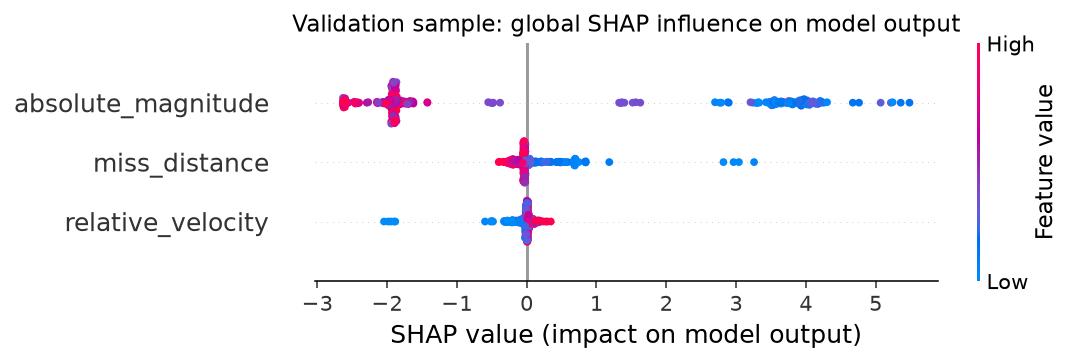

In [21]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import shap
from sklearn.inspection import permutation_importance

PHASE5_SEED = 42
SHAP_SAMPLE_SIZE = 300
permutation_result = permutation_importance(
    candidate, X_validation, y_validation, scoring='average_precision',
    n_repeats=10, random_state=PHASE5_SEED, n_jobs=1,
)
permutation_importance_table = pd.DataFrame({
    'feature': list(FEATURES),
    'mean_validation_pr_auc_decrease': permutation_result.importances_mean,
    'std_validation_pr_auc_decrease': permutation_result.importances_std,
}).sort_values('mean_validation_pr_auc_decrease', ascending=False, ignore_index=True)
print('Permutation importance: validation average-precision decrease after shuffling (10 repeats).')
print(permutation_importance_table.to_string(index=False))

shap_indices = (
    y_validation.groupby(y_validation).sample(
        n=None, frac=SHAP_SAMPLE_SIZE / len(y_validation), random_state=PHASE5_SEED
    ).index
)
# Deterministically top up only if rounding made the stratified sample smaller than 300.
if len(shap_indices) < SHAP_SAMPLE_SIZE:
    remaining = X_validation.index.difference(shap_indices)
    top_up = pd.Series(remaining).sample(
        n=SHAP_SAMPLE_SIZE - len(shap_indices), random_state=PHASE5_SEED
    ).tolist()
    shap_indices = shap_indices.append(pd.Index(top_up))
X_shap = X_validation.loc[sorted(shap_indices), list(FEATURES)].copy()
if len(X_shap) != SHAP_SAMPLE_SIZE:
    raise AssertionError(f'Expected {SHAP_SAMPLE_SIZE} SHAP rows, found {len(X_shap)}.')
tree_explainer = shap.TreeExplainer(candidate)
shap_explanation = tree_explainer(X_shap)
if shap_explanation.values.ndim == 3:
    # Select the hazardous/positive output if this SHAP version returns an output dimension.
    shap_explanation = shap.Explanation(
        values=shap_explanation.values[:, :, 1],
        base_values=np.asarray(shap_explanation.base_values)[:, 1],
        data=shap_explanation.data, feature_names=list(FEATURES),
    )
if shap_explanation.values.shape != X_shap.shape:
    raise AssertionError(f'Unexpected SHAP shape: {shap_explanation.values.shape}; expected {X_shap.shape}.')
shap_additivity_max_abs_error = float(np.max(np.abs(
    np.asarray(shap_explanation.base_values) + shap_explanation.values.sum(axis=1)
    - candidate.decision_function(X_shap)
)))
if shap_additivity_max_abs_error > 1e-6:
    raise AssertionError(f'SHAP additivity check failed: {shap_additivity_max_abs_error}.')
mean_absolute_shap = pd.DataFrame({
    'feature': list(FEATURES),
    'mean_absolute_shap_value': np.abs(shap_explanation.values).mean(axis=0),
}).sort_values('mean_absolute_shap_value', ascending=False, ignore_index=True)
print(f'\nSHAP uses a deterministic, label-stratified validation sample of {len(X_shap)} rows (seed={PHASE5_SEED}).')
print('SHAP sample historical-label counts:', y_validation.loc[X_shap.index].value_counts().sort_index().to_dict())
print('SHAP additivity max absolute error against decision_function:', shap_additivity_max_abs_error)
print(mean_absolute_shap.to_string(index=False))

plt.figure(figsize=(8, 4.8))
shap.plots.beeswarm(shap_explanation, max_display=len(FEATURES), show=False)
plt.title('Validation sample: global SHAP influence on model output')
plt.tight_layout()


### Phase 5 interpretation

In this frozen validation run, `absolute_magnitude` ranked first by both the mean validation PR-AUC decrease and mean absolute SHAP value, followed by `miss_distance`, then `relative_velocity`. A larger positive permutation decrease means shuffling that input reduced validation PR-AUC more; a larger mean absolute SHAP value means the feature moved the model's raw decision output on the 300-row sample. These are model associations that can be correlated or conditional on other inputs—not causal astronomical findings, validation of unresolved source units, or a physical-risk explanation.


Representative validation false positives: the five scores nearest the fixed threshold.
      id               name  absolute_magnitude  relative_velocity  miss_distance  hazardous  model_score  prediction_margin
 3548882        (2010 TY54)                21.6       20688.367541   3.247423e+07      False     0.099827           0.000475
54017096         (2020 KC1)                22.0       36645.790729   3.617327e+07      False     0.100477           0.001125
 3558373         (2011 EB7)                20.9       16544.532950   7.207330e+07      False     0.100511           0.001159
 3843051         (2019 MG2)                22.0       41064.382430   4.864718e+07      False     0.100660           0.001308
 2468837 468837 (2012 UP27)                21.0       15532.212820   6.482309e+07      False     0.100936           0.001583

Representative validation false negatives: the five scores nearest the fixed threshold.
     id                name  absolute_magnitude  relative_velocity  miss_

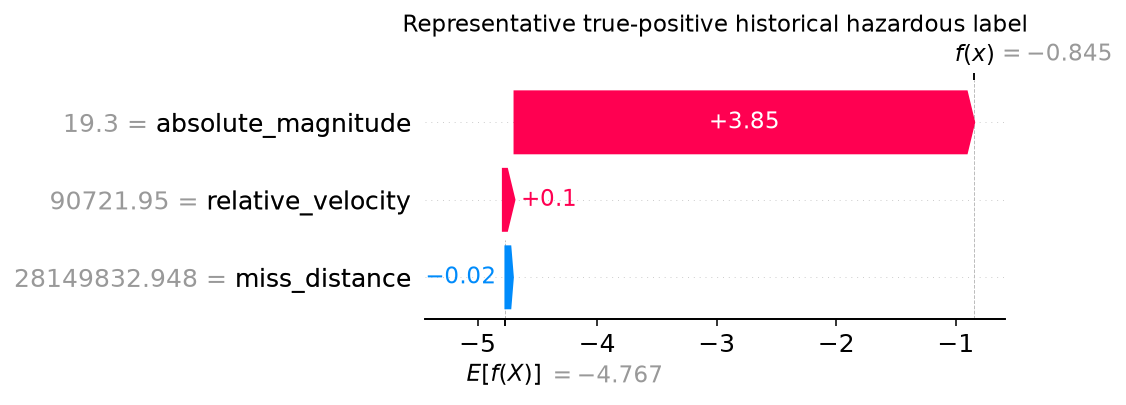

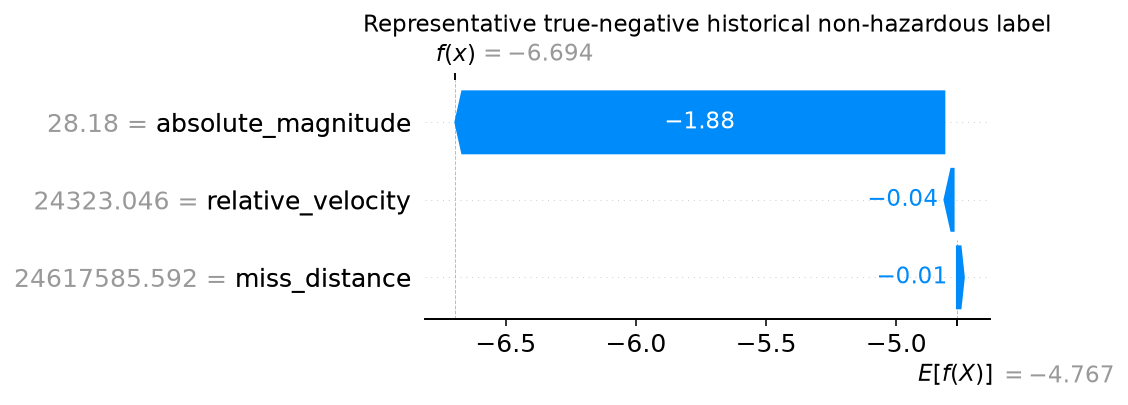

In [23]:
validation_predictions = (validation_scores >= selected_threshold).astype(int)
validation_review = frame.loc[X_validation.index, ['id', 'name', *FEATURES, 'hazardous']].copy()
validation_review['model_score'] = validation_scores
validation_review['predicted_hazardous'] = validation_predictions.astype(bool)
validation_review['prediction_margin'] = validation_review['model_score'] - selected_threshold

true_positive = validation_review[(validation_review['hazardous']) & (validation_review['predicted_hazardous'])]
true_negative = validation_review[(~validation_review['hazardous']) & (~validation_review['predicted_hazardous'])]
if true_positive.empty or true_negative.empty:
    raise RuntimeError('Validation partition lacks a true-positive or true-negative row for the requested SHAP waterfalls.')
def median_score_index(records):
    return (records['model_score'] - records['model_score'].median()).abs().sort_values(kind='mergesort').index[0]

hazardous_index = median_score_index(true_positive)
non_hazardous_index = median_score_index(true_negative)
shap_single = tree_explainer(X_validation.loc[[hazardous_index, non_hazardous_index], list(FEATURES)])
if shap_single.values.ndim == 3:
    shap_single = shap.Explanation(
        values=shap_single.values[:, :, 1],
        base_values=np.asarray(shap_single.base_values)[:, 1],
        data=shap_single.data, feature_names=list(FEATURES),
    )
for position, (label, row_index) in enumerate([
    ('Representative true-positive historical hazardous label', hazardous_index),
    ('Representative true-negative historical non-hazardous label', non_hazardous_index),
]):
    plt.figure(figsize=(8, 4.8))
    shap.plots.waterfall(shap_single[position], max_display=len(FEATURES), show=False)
    plt.title(label)
    plt.tight_layout()

false_positives = validation_review[(~validation_review['hazardous']) & (validation_review['predicted_hazardous'])].copy()
false_negatives = validation_review[(validation_review['hazardous']) & (~validation_review['predicted_hazardous'])].copy()
review_columns = ['id', 'name', *FEATURES, 'hazardous', 'model_score', 'prediction_margin']
representative_false_positives = false_positives.assign(
    distance_to_threshold=(false_positives['prediction_margin']).abs()
).sort_values(['distance_to_threshold', 'id'], kind='mergesort').head(5)[review_columns]
representative_false_negatives = false_negatives.assign(
    distance_to_threshold=(false_negatives['prediction_margin']).abs()
).sort_values(['distance_to_threshold', 'id'], kind='mergesort').head(5)[review_columns]
print('Representative validation false positives: the five scores nearest the fixed threshold.')
print(representative_false_positives.to_string(index=False))
print('\nRepresentative validation false negatives: the five scores nearest the fixed threshold.')
print(representative_false_negatives.to_string(index=False))
print('\nSelection is deterministic and descriptive; it does not change the fixed threshold or model.')


### Phase 5 limitations

The selected waterfall rows are deterministic validation examples closest to their group’s median score, not case studies with external astronomical verification. The false-positive and false-negative tables are selected by distance to the existing threshold so they document boundary cases; they must not be generalized into a causal error mechanism. The model estimates the CSV’s historical label only, and dataset source provenance, label definition, and source-level unit verification remain unresolved.


# Phase 6 — Deployment preparation, staged export, and limitations

This notebook only reads the existing staged candidate and its provenance. The legacy `sentinel_model.joblib` and its metadata are hash-audited and preserved byte-for-byte. The deterministic fixture had already verified the staged model reload at export time; no model, metadata, fixture, or report is written by this notebook. The test partition remains reserved and is intentionally unscored.


In [26]:
REFERENCE_FIXTURE_PATH = STAGING_DIR / 'reference_prediction_fixture.json'
STAGING_REPORT_PATH = STAGING_DIR / 'canonical_training_report_v1_1_0.json'
reference_fixture = json.loads(REFERENCE_FIXTURE_PATH.read_text(encoding='utf-8'))
staging_report = json.loads(STAGING_REPORT_PATH.read_text(encoding='utf-8'))
print(json.dumps({
    'staged_model': str(STAGED_CANDIDATE_PATH),
    'staged_metadata': str(STAGED_METADATA_PATH),
    'reference_fixture': str(REFERENCE_FIXTURE_PATH),
    'report': str(STAGING_REPORT_PATH),
    'reload_check': staging_report['staged_model']['reloaded_predictions_identical'],
    'test_partition_status': staging_report['test_partition_status'],
    'notebook_run_wrote_model_or_staging_artifacts': False,
}, indent=2))


{
  "staged_model": "/Users/baburreyan/Downloads/kartik-and-babur--main/sentinel_training/artifacts/staging/sentinel_model_candidate_v1_1_0.joblib",
  "staged_metadata": "/Users/baburreyan/Downloads/kartik-and-babur--main/sentinel_training/artifacts/staging/sentinel_model_candidate_v1_1_0.metadata.json",
  "reference_fixture": "/Users/baburreyan/Downloads/kartik-and-babur--main/sentinel_training/artifacts/staging/reference_prediction_fixture.json",
  "report": "/Users/baburreyan/Downloads/kartik-and-babur--main/sentinel_training/artifacts/staging/canonical_training_report_v1_1_0.json",
  "reload_check": true,
  "test_partition_status": "Reserved and intentionally not evaluated until the final evaluation step is authorized.",
  "notebook_run_wrote_model_or_staging_artifacts": false
}


## Limitations and next decision

- This model predicts the historical `hazardous` label in the supplied CSV. Its score is a model class score, not a calibrated physical impact probability.
- Dataset source provenance, label definition, and source-verified units remain unresolved.
- The candidate must receive a separately authorized, one-time final evaluation on the reserved benchmark test partition before any deployment decision.
- Deployment is intentionally unchanged: the running API continues to use legacy v1.0.0.
